# 📈 AI Trading Competition
### SDSU AI Club

**Your mission:** build a model that decides when to buy, sell, or sit out of a stock.
We'll test every team's model on real stock prices from a secret time period.

**How this works:**
1. Run the setup cells (Steps 1–3).
2. Try the two example strategies (Step 4).
3. Build your own in the workspace (Step 5). **Anything goes.** Use AI, change the examples, or start from scratch.
4. Submit (Step 6).

| | |
|---|---|
| **Teams** | 2–4 people |
| **Scoring** | 50% how well your model trades (Sharpe ratio, ranked in each round) + 50% how well you explain it |
| **Data rule** | Use only data from **2015 through 2024**, for training, testing, and choosing your model |
| **The test** | 3 secret rounds after 2024, each on a different stock: one lasts a year, one 6 months, one 3 months |
| **Bonus round** | 🚀 SpaceX (SPCX) from its June 2026 IPO. Just for fun, doesn't count toward your score |

🤖 **AI tools are encouraged.** But anyone on your team may be asked how your model works, so make sure you understand what you submit.

## Step 1 · Team info
Put in your team name and members, then run the cell (▶ button or **Shift+Enter**).

In [5]:
TEAM_NAME = "Team Example"
TEAM_MEMBERS = ["Name 1", "Name 2"]

## Step 2 · Setup
Run this cell. It loads the scoring code we'll use on competition day. You don't need to read or edit it.

In [6]:
# @title ⚙️ Setup: run this, no need to open it
import hashlib, inspect, json, subprocess, sys, tempfile, time, types
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

try:
    import cloudpickle
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'cloudpickle'], check=True)
    import cloudpickle

try:
    from IPython.display import display
except ImportError:
    display = print

plt.rcParams.update({'figure.figsize': (11, 4), 'axes.grid': True, 'grid.alpha': 0.25,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'text.parse_math': False})

WORK_DIR = (Path('/content') if Path('/content').exists() else Path.cwd()) / 'trading_competition'
WORK_DIR.mkdir(parents=True, exist_ok=True)

# The exact scoring engine the organizers use on competition day.
HARNESS_SOURCE = '"""SDSU AI Club trading harness v1.0.\n\nShare this exact file with the organizer-side builder. The member notebook embeds\nthe same bytes. This is a deterministic backtest, not a security sandbox.\n"""\nfrom __future__ import annotations\n\nimport math\nimport time\nfrom typing import Callable\n\nimport numpy as np\nimport pandas as pd\n\nHARNESS_VERSION = \'sdsu-trading-harness-v1.0\'\nOHLCV = [\'Open\', \'High\', \'Low\', \'Close\', \'Volume\']\nFEE_RATE = 0.001\nWARMUP_BARS = 252\nTRADING_DAYS_PER_YEAR = 252\n\n\nclass ContractError(ValueError):\n    """The submitted prediction function broke the published contract."""\n\n\ndef clean_frame(frame: pd.DataFrame) -> pd.DataFrame:\n    """Validate a daily OHLCV frame without filling missing prices."""\n    result = frame.copy()\n    if \'Date\' in result.columns:\n        result = result.set_index(\'Date\')\n    result.index = pd.DatetimeIndex(pd.to_datetime(result.index))\n    if result.index.tz is not None:\n        result.index = result.index.tz_localize(None)\n    result.index = result.index.normalize()\n    result.index.name = \'Date\'\n    if result.index.has_duplicates:\n        raise ValueError(\'Duplicate dates: one stock must have one row per day.\')\n    missing = set(OHLCV) - set(result.columns)\n    if missing:\n        raise ValueError(f\'Missing OHLCV columns: {sorted(missing)}\')\n    result = result[OHLCV].sort_index().astype(float)\n    result.attrs = {}\n    if len(result) == 0 or not np.isfinite(result.to_numpy()).all():\n        raise ValueError(\'Data must contain finite OHLCV values; inspect missing rows.\')\n    if (result[[\'Open\', \'High\', \'Low\', \'Close\']] <= 0).any().any():\n        raise ValueError(\'Prices must be positive.\')\n    if (result[\'Volume\'] < 0).any():\n        raise ValueError(\'Volume cannot be negative.\')\n    if (result[\'High\'] + 1e-6 < result[[\'Open\', \'Close\', \'Low\']].max(axis=1)).any():\n        raise ValueError(\'A High value is below another price in the same bar.\')\n    if (result[\'Low\'] - 1e-6 > result[[\'Open\', \'Close\', \'High\']].min(axis=1)).any():\n        raise ValueError(\'A Low value is above another price in the same bar.\')\n    return result\n\n\ndef checked_position(result) -> float:\n    if isinstance(result, (bool, np.bool_)) or not isinstance(result, (float, np.floating)):\n        raise ContractError(\'predict(history) must return a float, e.g. return float(0.5).\')\n    result = float(result)\n    if not math.isfinite(result) or not -1.0 <= result <= 1.0:\n        raise ContractError(f\'Position {result!r} is not a finite float between -1 and 1.\')\n    return result\n\n\ndef smoke_check_predict(predict: Callable) -> dict:\n    """Check unseen dummy OHLCV input; this data is never used for training."""\n    rng = np.random.default_rng(812)\n    close = 100 * np.exp(np.cumsum(rng.normal(0, .008, WARMUP_BARS)))\n    history = pd.DataFrame({\n        \'Open\': close * .999,\n        \'High\': close * 1.01,\n        \'Low\': close * .99,\n        \'Close\': close,\n        \'Volume\': rng.integers(100_000, 1_000_000, WARMUP_BARS).astype(float),\n    }, index=pd.bdate_range(\'2020-01-02\', periods=WARMUP_BARS, name=\'Date\'))\n    before = history.copy(deep=True)\n    start = time.perf_counter()\n    first = checked_position(predict(history))\n    elapsed = time.perf_counter() - start\n    if not history.equals(before):\n        raise ContractError(\'predict() modified its input. Work on a copy instead.\')\n    second = checked_position(predict(before.copy(deep=True)))\n    if abs(first - second) > 1e-10:\n        raise ContractError(\'Identical histories must produce identical positions.\')\n    flat = before.copy()\n    flat[[\'Open\', \'High\', \'Low\', \'Close\']] = 100.0\n    checked_position(predict(flat))\n    return {\'dummy_position\': first, \'seconds_per_call\': round(elapsed, 4), \'passed\': True}\n\n\ndef _rebalance(cash: float, shares: float, price: float, target: float, fee: float):\n    """Solve for target exposure as a fraction of equity AFTER transaction fees."""\n    equity = cash + shares * price\n    if equity <= 0:\n        raise ContractError(\'A stock allocation became insolvent (equity <= 0).\')\n    gap = target * equity - shares * price\n    denominator = 1.0 + target * fee if gap >= 0 else 1.0 - target * fee\n    notional = gap / denominator\n    cost = fee * abs(notional)\n    cash -= notional + cost\n    shares += notional / price\n    after = cash + shares * price\n    if after <= 0:\n        raise ContractError(\'Transaction fees exhausted a stock allocation.\')\n    if abs(shares * price) > after * (1 + 1e-9):\n        raise ContractError(\'Gross exposure exceeded the no-leverage limit.\')\n    return cash, shares, cost, abs(notional)\n\n\ndef performance_metrics(equity: pd.Series) -> dict:\n    daily = equity.pct_change().dropna()\n    sigma = float(daily.std(ddof=1)) if len(daily) >= 2 else 0.0\n    sharpe = float(np.sqrt(TRADING_DAYS_PER_YEAR) * daily.mean() / sigma) if sigma > 1e-12 else 0.0\n    drawdown = equity / equity.cummax() - 1\n    return {\n        \'Sharpe\': sharpe,\n        \'Total return\': float(equity.iloc[-1] / equity.iloc[0] - 1),\n        \'Max drawdown\': float(drawdown.min()),\n        \'Final equity\': float(equity.iloc[-1]),\n        \'Intervals\': int(len(daily)),\n    }\n\n\ndef run_backtest(data: dict, predict: Callable, start: str, end: str,\n                 initial_capital: float = 10_000.0, fee_rate: float = FEE_RATE,\n                 warmup_bars: int = WARMUP_BARS, budget_seconds: float = 120.0) -> dict:\n    """Observe prior close -> trade next open -> mark at the following open.\n\n    `start` and `end` inclusively select execution/mark dates. The final selected\n    open liquidates all holdings; it is not an additional prediction date.\n    Each stock starts with an equal independent allocation. Allocations are not\n    rebalanced across stocks. No interest, dividends, borrow charges, or slippage\n    beyond the specified fee are separately credited/debited.\n    """\n    if not data or initial_capital <= 0 or not 0 <= fee_rate < .1:\n        raise ValueError(\'Supply stock data, positive capital, and a valid fee rate.\')\n    frames = {str(name): clean_frame(frame) for name, frame in data.items()}\n    dates = None\n    for frame in frames.values():\n        dates = frame.index if dates is None else dates.intersection(frame.index)\n    dates = dates[(dates >= pd.Timestamp(start)) & (dates <= pd.Timestamp(end))].sort_values()\n    if len(dates) < 3:\n        raise ValueError(\'Choose a window containing at least three common trading dates.\')\n    deadline = time.perf_counter() + budget_seconds\n    allocation = initial_capital / len(frames)\n    curves, trades = {}, []\n    total_fees = 0.0\n    for name, frame in frames.items():\n        first = frame.index.get_loc(dates[0])\n        if first < warmup_bars:\n            raise ValueError(f\'{name}: need {warmup_bars} earlier bars before the window starts.\')\n        history_start = first - warmup_bars\n        cash, shares = float(allocation), 0.0\n        values = [allocation]\n        for k, date in enumerate(dates[:-1]):\n            if time.perf_counter() > deadline:\n                raise TimeoutError(\'Local backtest budget exceeded. Simplify predict(); never train inside it.\')\n            at = frame.index.get_loc(date)\n            history = frame.iloc[history_start:at][OHLCV].copy(deep=True)\n            history.attrs = {}\n            position = checked_position(predict(history))\n            if time.perf_counter() > deadline:\n                raise TimeoutError(\'Local backtest budget exceeded during a prediction.\')\n            price = float(frame.at[date, \'Open\'])\n            cash, shares, cost, turnover = _rebalance(cash, shares, price, position, fee_rate)\n            total_fees += cost\n            if turnover > 1e-8:\n                trades.append({\'Stock\': name, \'Execution date\': date,\n                               \'History through\': history.index[-1], \'Target\': position,\n                               \'Notional traded\': turnover, \'Fee\': cost})\n            marked = cash + shares * float(frame.at[dates[k + 1], \'Open\'])\n            if marked <= 0:\n                raise ContractError(f\'{name}: a stock allocation became insolvent. Reduce exposure or shorting.\')\n            values.append(marked)\n        exit_price = float(frame.at[dates[-1], \'Open\'])\n        cash, shares, cost, turnover = _rebalance(cash, shares, exit_price, 0.0, fee_rate)\n        total_fees += cost\n        values[-1] = cash\n        if turnover > 1e-8:\n            trades.append({\'Stock\': name, \'Execution date\': dates[-1],\n                           \'History through\': pd.NaT, \'Target\': 0.0,\n                           \'Notional traded\': turnover, \'Fee\': cost})\n        curves[name] = pd.Series(values, index=dates)\n    by_stock = pd.DataFrame(curves)\n    equity = by_stock.sum(axis=1).rename(\'Portfolio equity\')\n    metrics = performance_metrics(equity)\n    metrics[\'Fees paid\'] = total_fees\n    metrics[\'Trades\'] = len(trades)\n    return {\'equity\': equity, \'daily_returns\': equity.pct_change().dropna(),\n            \'by_stock\': by_stock, \'trades\': pd.DataFrame(trades), \'metrics\': metrics,\n            \'harness_version\': HARNESS_VERSION}\n\n\ndef buy_and_hold(history: pd.DataFrame) -> float:\n    return 1.0\n'
harness = types.ModuleType('sdsu_harness')
exec(compile(HARNESS_SOURCE, 'sdsu_harness.py', 'exec'), harness.__dict__)
HARNESS_SHA = hashlib.sha256(HARNESS_SOURCE.encode()).hexdigest()

FIRST_ALLOWED, LAST_ALLOWED = pd.Timestamp('2015-01-01'), pd.Timestamp('2024-12-31')
PRACTICE_START, PRACTICE_END = '2023-01-01', '2023-12-31'
PRACTICE_STOCKS = ['AAPL', 'JPM', 'XOM', 'JNJ']
DATA = {}
ATTEMPTS = []
ROBUSTNESS_RUNS = []
_latest_training_end = None
STOCK_GROUPS = {
    'Big tech': ['AAPL', 'MSFT', 'NVDA', 'META'],
    'Steady': ['JNJ', 'PG', 'KO', 'DUK'],
    'Struggling': ['INTC', 'F', 'M', 'HOG'],
    'Volatile': ['PLUG', 'AAL', 'CROX', 'BA'],
}
TEST_YEARS_STOCKS = ['JPM', 'XOM', 'PFE', 'CROX', 'M']


def split_by_stock(prices):
    """Turn the long price table into {ticker: daily prices}."""
    prices = prices.copy()
    prices['Date'] = pd.to_datetime(prices['Date'])
    if prices['Date'].min() < FIRST_ALLOWED or prices['Date'].max() > LAST_ALLOWED:
        raise ValueError('This file has dates outside 2015-2024, which is not allowed.')
    return {ticker: harness.clean_frame(group.drop(columns='Ticker'))
            for ticker, group in prices.groupby('Ticker', sort=True)}


def show_stock(ticker, start=None, end=None):
    """Plot a stock's closing price."""
    DATA[ticker]['Close'].loc[start:end].plot(title=f'{ticker} closing price', ylabel='Price ($)')
    plt.show()


def training_data(end='2022-12-31', stocks=None):
    """Get price data up to (and including) `end`. Never later than 2024-12-31."""
    global _latest_training_end
    end = pd.Timestamp(end)
    if end > LAST_ALLOWED:
        raise ValueError('Training data must end on or before 2024-12-31.')
    if _latest_training_end is None or end > _latest_training_end:
        _latest_training_end = end
    stocks = stocks or sorted(DATA)
    return {t: DATA[t].loc[:end].copy() for t in stocks}


def add_stock_csv(path, ticker):
    """Optional: add your own stock. CSV columns: Date, Open, High, Low, Close, Volume."""
    frame = harness.clean_frame(pd.read_csv(path))
    if frame.index.min() < FIRST_ALLOWED or frame.index.max() > LAST_ALLOWED:
        raise ValueError(f'{path}: every row must be between 2015-01-01 and 2024-12-31.')
    DATA[ticker.upper()] = frame
    print(f'Added {ticker.upper()}: {len(frame)} days of data.')


def _source_of(fn):
    try:
        return inspect.getsource(fn)
    except (OSError, TypeError):
        return '(source not available)'


def practice_score(predict, note='', stocks=None, start=PRACTICE_START, end=PRACTICE_END):
    """Test a predict function on the practice period, compared with buy-and-hold."""
    if _latest_training_end is not None and _latest_training_end >= pd.Timestamp(start):
        print(f'⚠️  Heads up: you loaded training data through {_latest_training_end.date()}, which '
              f'overlaps this practice period. If your model trained on it, this score is too optimistic.\n')
    practice = {t: DATA[t] for t in (stocks or PRACTICE_STOCKS)}
    try:
        yours = harness.run_backtest(practice, predict, start, end)
    except (harness.ContractError, TimeoutError) as error:
        print('❌ Your predict function has a problem:', error)
        return None
    hold = harness.run_backtest(practice, harness.buy_and_hold, start, end)
    table = pd.DataFrame({'Your model': yours['metrics'], 'Buy and hold': hold['metrics']}).T
    table = table[['Sharpe', 'Total return', 'Max drawdown', 'Trades', 'Fees paid']]
    shown = table.copy()
    shown['Sharpe'] = table['Sharpe'].map('{:.2f}'.format)
    shown['Total return'] = table['Total return'].map('{:.1%}'.format)
    shown['Max drawdown'] = table['Max drawdown'].map('{:.1%}'.format)
    shown['Trades'] = table['Trades'].map('{:.0f}'.format)
    shown['Fees paid'] = table['Fees paid'].map('${:,.0f}'.format)
    display(shown)
    ax = yours['equity'].plot(label='Your model', linewidth=2)
    hold['equity'].plot(ax=ax, label='Buy and hold', linewidth=1.2, alpha=0.8)
    ax.set(title=f'Practice: {start} to {end} on {", ".join(practice)}', ylabel='Portfolio value ($)')
    ax.legend()
    plt.show()
    ATTEMPTS.append({'Attempt': len(ATTEMPTS) + 1, 'Time': datetime.now().strftime('%H:%M:%S'),
                     'Note': note, 'Sharpe': round(yours['metrics']['Sharpe'], 3),
                     'Return': round(yours['metrics']['Total return'], 4),
                     'Trades': yours['metrics']['Trades'], 'code': _source_of(predict)})
    print(f'Saved as attempt #{len(ATTEMPTS)}. Sharpe: {yours["metrics"]["Sharpe"]:.2f}')
    return yours['metrics']['Sharpe']


def robustness_check(predict, note='', trained_through='auto'):
    """Test across several years and stock groups. Shows whether an edge is consistent or a fluke."""
    if trained_through == 'auto':
        trained_to = _latest_training_end
    else:
        trained_to = pd.Timestamp(trained_through) if trained_through else None
    rows = []
    def run(label, stocks, start, end):
        stocks = [s for s in stocks if s in DATA]
        if not stocks:
            return
        honest = trained_to is None or pd.Timestamp(start) > trained_to
        try:
            yours = harness.run_backtest({s: DATA[s] for s in stocks}, predict, start, end, budget_seconds=300)
        except (harness.ContractError, TimeoutError) as error:
            print('❌ Your predict function has a problem:', error)
            raise
        hold = harness.run_backtest({s: DATA[s] for s in stocks}, harness.buy_and_hold, start, end)
        rows.append({'Test': label, 'Stocks': ', '.join(stocks),
                     'Your Sharpe': yours['metrics']['Sharpe'], 'Buy & hold Sharpe': hold['metrics']['Sharpe'],
                     'Your return': yours['metrics']['Total return'],
                     'Honest?': 'yes' if honest else 'no: model saw this data'})
    print('Testing across years...')
    try:
        for year in range(2020, 2025):
            run(str(year), TEST_YEARS_STOCKS, f'{year}-01-01', f'{year}-12-31')
        group_year = 2024
        if trained_to is not None and trained_to >= pd.Timestamp('2024-01-01'):
            print('(Skipping stock groups: your model trained into 2024, so there is no unseen year left.)')
        else:
            print(f'Testing across stock groups in {group_year}...')
            for name, stocks in STOCK_GROUPS.items():
                run(f'{name} ({group_year})', stocks, f'{group_year}-01-01', f'{group_year}-12-31')
    except (harness.ContractError, TimeoutError):
        return None
    table = pd.DataFrame(rows).set_index('Test')
    shown = table.copy()
    for column in ['Your Sharpe', 'Buy & hold Sharpe']:
        shown[column] = table[column].map('{:.2f}'.format)
    shown['Your return'] = table['Your return'].map('{:.1%}'.format)
    display(shown)
    honest = table[table['Honest?'] == 'yes']
    if honest.empty:
        print('⚠️  Every test overlapped your training data, so none of these scores are honest.')
        print('   Retrain with an earlier end date (for example 2021-12-31) and run this again.')
    else:
        positive = int((honest['Your Sharpe'] > 0).sum())
        beat = int((honest['Your Sharpe'] > honest['Buy & hold Sharpe']).sum())
        print(f'Honest tests: {len(honest)}. Positive Sharpe in {positive}. Beat buy-and-hold in {beat}.')
        print(f'Typical (median) honest Sharpe: {honest["Your Sharpe"].median():.2f}')
        if len(honest) < len(table):
            print('Rows marked "no" overlap your training data. Their scores look better than they really are.')
            print('If your model is a hand-written rule that never trains on data, use:')
            print('   robustness_check(predict, trained_through=None)')
    ROBUSTNESS_RUNS.append({'Time': datetime.now().strftime('%H:%M:%S'), 'Note': note,
                            'results': table.reset_index().to_dict('records'), 'code': _source_of(predict)})
    return table


def _action(previous, target):
    if abs(target - previous) < 1e-9:
        return 'HOLD'
    if target > previous:
        return 'BUY' if target > 0 else 'COVER'
    return 'SELL' if target >= 0 else 'SHORT'


def _simulate_for_watching(predict, stocks, start, end, money):
    """Run the official scoring engine, recording every daily decision."""
    allocation = money / len(stocks)
    per_stock = {}
    for stock in stocks:
        decisions = []
        def recorder(history, _predict=predict, _log=decisions):
            position = _predict(history)
            _log.append(position)
            return position
        result = harness.run_backtest({stock: DATA[stock]}, recorder, start, end, initial_capital=allocation)
        hold = harness.run_backtest({stock: DATA[stock]}, harness.buy_and_hold, start, end, initial_capital=allocation)
        dates = result['equity'].index
        trades = result['trades']
        fees = trades.groupby('Execution date')['Fee'].sum() if len(trades) else pd.Series(dtype=float)
        per_stock[stock] = pd.DataFrame({
            'Price': DATA[stock].loc[dates, 'Open'].to_numpy(),
            'Position': [float(p) for p in decisions] + [0.0],
            'Value': result['equity'].to_numpy(),
            'Hold value': hold['equity'].to_numpy(),
            'Fee': fees.reindex(dates).fillna(0.0).to_numpy(),
        }, index=dates)
        previous, actions = 0.0, []
        for position in per_stock[stock]['Position']:
            actions.append(_action(previous, position))
            previous = position
        actions[-1] = 'CLOSE' if previous != 0 or per_stock[stock]['Position'].iloc[-2] != 0 else 'HOLD'
        per_stock[stock]['Action'] = actions
    return per_stock


def _draw_frame(fig, per_stock, k, money, start, end):
    fig.clf()
    grid = fig.add_gridspec(2, 3, height_ratios=[1, 1.1], width_ratios=[1, 1, 0.9], hspace=0.35, wspace=0.3)
    ax_money = fig.add_subplot(grid[0, :2])
    ax_price = fig.add_subplot(grid[1, :2])
    ax_text = fig.add_subplot(grid[:, 2])
    ax_text.axis('off')
    dates = next(iter(per_stock.values())).index
    shown = dates[:k + 1]
    total = sum(frame['Value'] for frame in per_stock.values())
    hold_total = sum(frame['Hold value'] for frame in per_stock.values())
    fees_so_far = sum(frame['Fee'].iloc[:k + 1].sum() for frame in per_stock.values())

    ax_money.plot(shown, total.iloc[:k + 1], linewidth=2.2, color='#2563eb', label='Your model')
    ax_money.plot(shown, hold_total.iloc[:k + 1], linewidth=1.2, color='#9ca3af', label='Buy and hold')
    ax_money.axhline(money, color='#d1d5db', linewidth=0.8, linestyle='--')
    ax_money.set_xlim(dates[0], dates[-1])
    ax_money.set_ylabel('Account value ($)')
    ax_money.legend(loc='upper left', fontsize=9)
    ax_money.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'${v:,.0f}'))

    palette = ['#2563eb', '#f59e0b', '#7c3aed', '#0891b2', '#db2777', '#78716c', '#65a30d', '#1e3a8a']
    for i, (stock, frame) in enumerate(per_stock.items()):
        change = frame['Price'] / frame['Price'].iloc[0] * 100 - 100
        ax_price.plot(shown, change.iloc[:k + 1], linewidth=1.3, label=stock, color=palette[i % len(palette)])
        recent = frame.iloc[:k + 1]
        buys = recent['Action'].isin(['BUY', 'COVER'])
        sells = recent['Action'].isin(['SELL', 'SHORT', 'CLOSE'])
        ax_price.scatter(recent.index[buys], change.iloc[:k + 1][buys], marker='^', s=28,
                         color='#16a34a', zorder=3, edgecolors='white', linewidths=0.4)
        ax_price.scatter(recent.index[sells], change.iloc[:k + 1][sells], marker='v', s=28,
                         color='#dc2626', zorder=3, edgecolors='white', linewidths=0.4)
    ax_price.set_xlim(dates[0], dates[-1])
    for axis in (ax_money, ax_price):
        axis.xaxis.set_major_locator(mdates.MonthLocator())
        axis.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    ax_price.set_ylabel('Stock price change (%)')
    ax_price.legend(loc='upper left', fontsize=8, ncol=min(4, len(per_stock)))
    ax_price.set_title('Green = buy, red = sell/short', fontsize=9, loc='right', color='#6b7280')

    now = dates[k]
    value = total.iloc[k]
    profit = value - money
    fig.suptitle(f'Day {k + 1} of {len(dates)}  |  {now:%a %b %d, %Y}  |  Account ${value:,.0f}  '
                 f'({profit:+,.0f}, {profit / money:+.1%})  |  Fees so far ${fees_so_far:,.0f}',
                 fontsize=12, fontweight='bold', x=0.02, ha='left')

    invested_total = sum(abs(frame['Position'].iloc[k]) * frame['Value'].iloc[k] for frame in per_stock.values())
    lines = ['MONEY RIGHT NOW', '',
             f'Invested  ${invested_total:,.0f}',
             f'Cash      ${max(value - invested_total, 0):,.0f}',
             f'Total     ${value:,.0f}', '',
             'EACH STOCK TODAY', '']
    for stock, frame in per_stock.items():
        row = frame.iloc[k]
        size = abs(row['Position'])
        state = 'all cash' if size == 0 else f"{size:.0%} {'long' if row['Position'] > 0 else 'short'}"
        gain = row['Value'] - money / len(per_stock)
        lines.append(f"{stock:<6}{row['Action']:<6}-> {state}")
        lines.append(f"      ${row['Value']:,.0f} ({'+' if gain >= 0 else '-'}${abs(gain):,.0f})")
    lines += ['', 'RECENT TRADES', '']
    log = []
    for stock, frame in per_stock.items():
        recent = frame.iloc[:k + 1]
        for date, row in recent[recent['Action'] != 'HOLD'].iterrows():
            log.append((date, f"{date:%b %d} {stock:<5}{row['Action']:<6}@ ${row['Price']:,.2f}"))
    for _, text in sorted(log)[-8:][::-1]:
        lines.append(text)
    if not log:
        lines.append('(no trades yet)')
    ax_text.text(0, 1, '\n'.join(lines), va='top', ha='left', family='monospace', fontsize=9.5,
                 transform=ax_text.transAxes)


def watch_trading(predict, stocks=None, start=PRACTICE_START, end=PRACTICE_END, money=10_000, speed='normal'):
    """Watch your model trade day by day, then see the final results.

    speed: 'slow', 'normal', 'fast', or 'instant' (skip straight to the results).
    """
    stocks = stocks or PRACTICE_STOCKS
    if _latest_training_end is not None and _latest_training_end >= pd.Timestamp(start):
        print(f'⚠️  Your training data goes through {_latest_training_end.date()}, which overlaps this period. '
              f'Results will look better than they really are.\n')
    print('Running the simulation...')
    try:
        per_stock = _simulate_for_watching(predict, stocks, start, end, money)
    except (harness.ContractError, TimeoutError) as error:
        print('❌ Your predict function has a problem:', error)
        return None
    days = len(next(iter(per_stock.values())))
    step = {'slow': 1, 'normal': 2, 'fast': 5}.get(speed)
    fig = plt.figure(figsize=(14, 7.5))
    try:
        from IPython.display import display as _show
        handle = _show(fig, display_id=True) if step else None
    except ImportError:
        handle = None
    plt.close(fig)
    if handle is not None:
        for k in list(range(0, days, step)) + [days - 1]:
            _draw_frame(fig, per_stock, k, money, start, end)
            handle.update(fig)
    else:
        _draw_frame(fig, per_stock, days - 1, money, start, end)
        try:
            _show(fig)
        except NameError:
            pass

    total = sum(frame['Value'] for frame in per_stock.values())
    hold_total = sum(frame['Hold value'] for frame in per_stock.values())
    yours = harness.performance_metrics(total)
    hold = harness.performance_metrics(hold_total)
    rows = []
    for stock, frame in per_stock.items():
        start_money = money / len(per_stock)
        rows.append({'Stock': stock, 'Started with': start_money, 'Ended with': frame['Value'].iloc[-1],
                     'Profit': frame['Value'].iloc[-1] - start_money,
                     'Trades': int((frame['Action'] != 'HOLD').sum()), 'Fees': frame['Fee'].sum(),
                     'Buy & hold profit': frame['Hold value'].iloc[-1] - start_money})
    table = pd.DataFrame(rows).set_index('Stock')
    table.loc['TOTAL'] = table.sum()
    table['Trades'] = table['Trades'].astype(int)
    for column in ['Started with', 'Ended with', 'Profit', 'Fees', 'Buy & hold profit']:
        table[column] = table[column].map(lambda v: f'${v:,.0f}' if v >= 0 else f'-${-v:,.0f}')
    print('\n📊 FINAL RESULTS')
    display(table)
    profit = total.iloc[-1] - money
    print(f'Net profit: ${profit:,.2f} ({profit / money:+.1%})   |   Buy and hold: '
          f'${hold_total.iloc[-1] - money:,.2f} ({hold["Total return"]:+.1%})')
    print(f'Sharpe (competition score): {yours["Sharpe"]:.2f}   |   Buy and hold: {hold["Sharpe"]:.2f}')
    print(f'Worst drop from a peak: {yours["Max drawdown"]:.1%}')
    return per_stock


def show_attempts():
    """Table of every practice run so far."""
    if not ATTEMPTS:
        print('No attempts yet. Run practice_score(...) first.')
        return
    display(pd.DataFrame(ATTEMPTS).drop(columns='code').set_index('Attempt'))


_CHECK_IN_FRESH_PYTHON = r"""
import sys, cloudpickle, numpy as np, pandas as pd
bundle = cloudpickle.load(open(sys.argv[1], 'rb'))
rng = np.random.default_rng(7)
close = 100 * np.exp(np.cumsum(rng.normal(0, 0.01, 300)))
history = pd.DataFrame({'Open': close * 0.999, 'High': close * 1.01, 'Low': close * 0.99,
                        'Close': close, 'Volume': np.full(300, 1e6)},
                       index=pd.bdate_range('2021-01-04', periods=300, name='Date'))
position = bundle['predict'](history)
assert isinstance(position, (float, np.floating)) and -1 <= position <= 1, position
print('ok')
"""


def save_submission(predict):
    """Check your predict function, then save it into one file for upload."""
    if not ATTEMPTS:
        print('⚠️  You have no practice attempts yet. Run practice_score(predict) at least once first.\n')
    try:
        check = harness.smoke_check_predict(predict)
    except Exception as error:
        print('❌ Not saved. Your predict function failed a basic check:', error)
        return
    short = harness.clean_frame(pd.DataFrame(
        {'Open': 100.0, 'High': 101.0, 'Low': 99.0, 'Close': 100.0, 'Volume': 1e6},
        index=pd.bdate_range('2026-06-12', periods=5, name='Date')))
    try:
        harness.checked_position(predict(short))
        bonus_ready = True
    except Exception as error:
        bonus_ready = False
        print('⚠️  Heads up: your model crashes with only a few days of history:', error)
        print('   It will sit out the SpaceX bonus round. Fix: return 0.0 when there is not enough data.\n')
    try:
        ip = get_ipython()  # noqa: F821 (exists inside Colab/Jupyter)
        cell_history = [cell for cell in ip.user_ns.get('In', []) if cell.strip()]
    except NameError:
        cell_history = []
    bundle = {
        'predict': predict,
        'team_name': TEAM_NAME,
        'team_members': TEAM_MEMBERS,
        'saved_at': datetime.now().isoformat(timespec='seconds'),
        'latest_training_data_end': str(_latest_training_end.date()) if _latest_training_end is not None else None,
        'practice_attempts': ATTEMPTS,
        'robustness_checks': ROBUSTNESS_RUNS,
        'cell_history': cell_history,
        'predict_source': _source_of(predict),
        'harness_sha256': HARNESS_SHA,
        'handles_short_history': bonus_ready,
        'python_version': sys.version.split()[0],
    }
    try:
        payload = cloudpickle.dumps(bundle)
    except Exception as error:
        print('❌ Not saved. Your model could not be packaged:', error)
        print('   Ask an organizer. Usually this means predict() uses something that cannot be saved, like an open file.')
        return
    if len(payload) > 100_000_000:
        print(f'❌ Not saved. Your submission is {len(payload) / 1e6:.0f} MB; the limit is 100 MB. Try a smaller model.')
        return
    slug = ''.join(c if c.isalnum() else '_' for c in TEAM_NAME).strip('_') or 'team'
    path = WORK_DIR / f'{slug}_submission.pkl'
    path.write_bytes(payload)
    result = subprocess.run([sys.executable, '-c', _CHECK_IN_FRESH_PYTHON, str(path)],
                            capture_output=True, text=True, timeout=120)
    if result.returncode != 0:
        print('❌ Saved, but the file does not work outside this notebook. Show this to an organizer:')
        print(result.stderr[-1500:])
        return
    print(f'✅ {path.name} saved and checked ({len(payload) / 1e6:.1f} MB).')
    print(f'   Test position on sample data: {check["dummy_position"]}')
    try:
        from google.colab import files
        files.download(str(path))
    except ImportError:
        print('   File location:', path)
    return path


print('✅ Setup done.')

✅ Setup done.


## Step 3 · Load the data
**Where it comes from:** daily prices for 12 well-known stocks from Yahoo Finance, January 2015 through
December 2024. Organizers downloaded it ahead of time and posted it as one file, so the whole room isn't
hitting Yahoo at once. You can open the link in your browser to see the raw file.

Each row is one stock on one day:
- **Open:** price when the market opened
- **High / Low:** highest and lowest price that day
- **Close:** price when the market closed
- **Volume:** how many shares were traded

In [ ]:
DATA_URL = "PASTE DATA URL HERE"

if DATA_URL.startswith("PASTE"):
    raise ValueError("The data link hasn't been filled in yet. Ask an organizer.")
prices = pd.read_csv(DATA_URL)
DATA = split_by_stock(prices)

print(f"Loaded {len(DATA)} stocks:", ", ".join(DATA))
prices.head()

Loaded 34 stocks: AAL, AAPL, AMZN, BA, C, CAT, CROX, CVX, DIS, DUK, F, GIS, GOOGL, HOG, HON, INTC, JNJ, JPM, KO, M, META, MMM, MSFT, NEE, NKE, NVDA, PFE, PG, PLUG, T, UNH, VZ, WMT, XOM


,Date,Ticker,Open,High,Low,Close,Volume
0,2015-01-02,AAL,51.430489,51.733690,50.284011,51.079914,10748600
1,2015-01-02,AAPL,24.627205,24.638260,23.734002,24.171761,212818400
2,2015-01-02,AMZN,15.629000,15.737500,15.348000,15.426000,55664000
3,2015-01-02,BA,114.636798,115.310248,112.905035,113.657211,4294200
4,2015-01-02,C,39.884954,40.127080,39.466735,39.811581,11137800


### Take a look
Change the ticker to look at other stocks. Try `'NVDA'` or `'XOM'`.

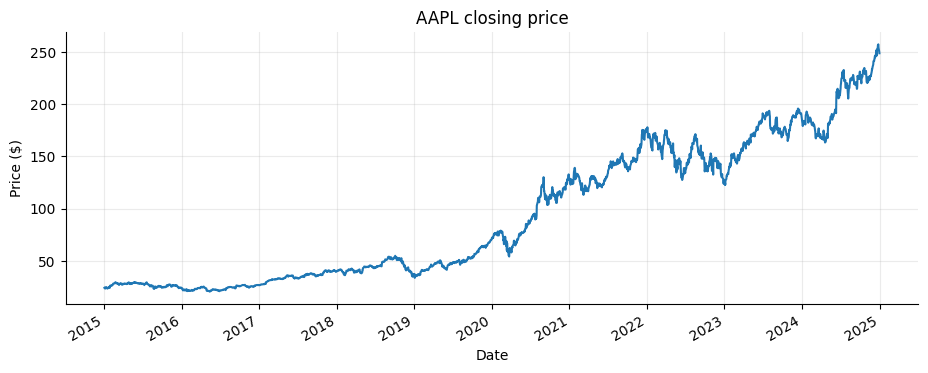

,Open,High,Low,Close,Volume
Date,,,,,
2024-12-24,253.649270,256.349660,253.450699,256.339752,23234700.0
2024-12-26,256.329802,258.226044,255.773839,257.153809,27237100.0
2024-12-27,255.972402,256.836160,251.236779,253.748550,42355300.0
2024-12-30,250.412763,251.673617,248.943430,250.382980,35557500.0
2024-12-31,250.621250,251.455194,247.632926,248.615799,39480700.0


In [8]:
show_stock('AAPL')
DATA['AAPL'].tail()

## Step 4 · How your model trades

Your model is a function called **`predict`**. Every trading day, we hand it the price history of
one stock (like the table above) and it answers with one number:

| Return | Meaning |
|---|---|
| `1.0` | Buy: all in on this stock |
| `0.5` | Half in |
| `0.0` | Stay in cash |
| `-1.0` | Short: bet the price will fall |

Any number between -1 and 1 works. A few details:
- The model **never knows which stock it's looking at.** It only sees prices.
- It decides after the market closes, and the trade happens at the **next morning's open**.
- Every trade costs a **0.1% fee**, so trading constantly gets expensive.

### Example 1 · A simple rule (no machine learning)
"If the stock's recent average price is above its longer-term average, the trend is up, so buy."

,Sharpe,Total return,Max drawdown,Trades,Fees paid
Your model,0.14,0.9%,-7.5%,22,$54
Buy and hold,1.19,16.1%,-10.7%,8,$22


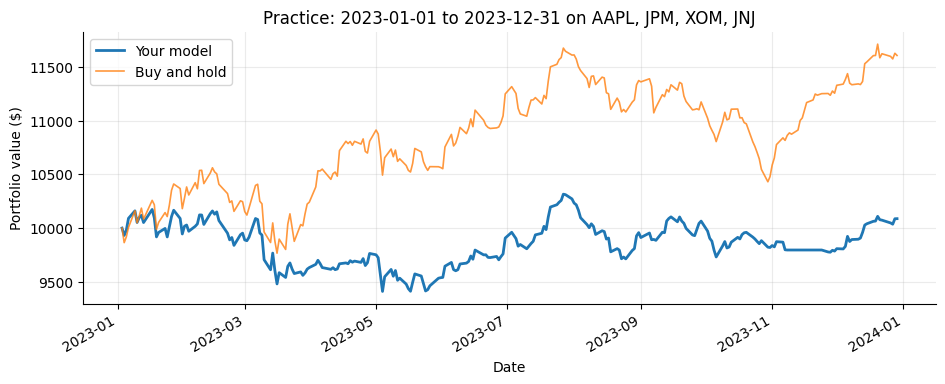

Saved as attempt #1. Sharpe: 0.14


0.13907215127560807

In [9]:
def predict_trend(history):
    close = history['Close']
    recent_average = close.tail(20).mean()      # last 20 days (about 1 month)
    longer_average = close.tail(100).mean()     # last 100 days (about 5 months)

    if recent_average > longer_average:
        return 1.0    # trend is up: buy
    else:
        return 0.0    # trend is down: stay in cash


practice_score(predict_trend, note="Example 1: 20-day vs 100-day average")

**How to read this:** practice runs on 2023 data your model never saw.
**Sharpe** is the competition score: return divided by how bumpy the ride was. Higher is better.
Compare against **buy and hold**, which just buys on day one and never sells.

### Example 2 · A machine learning model
Instead of us writing the rule, the model **learns** one from 2015–2022 data. We give it a few
*features* (facts about recent prices) and the answer for each past day (did the price go up?).

,Sharpe,Total return,Max drawdown,Trades,Fees paid
Your model,0.85,8.1%,-8.4%,216,$584
Buy and hold,1.19,16.1%,-10.7%,8,$22


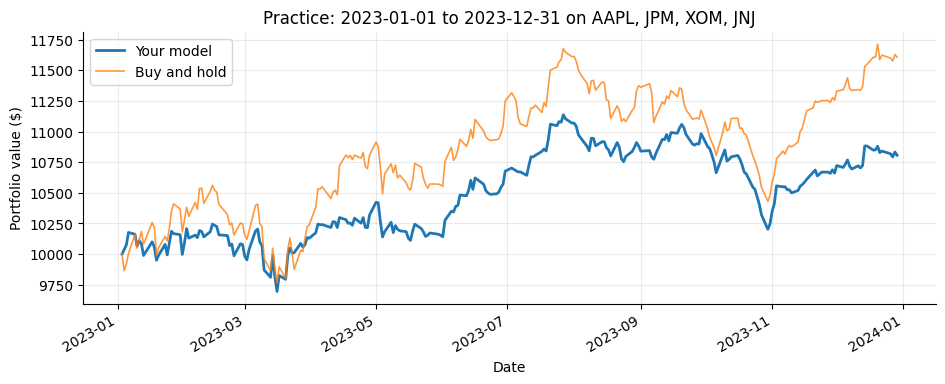

Saved as attempt #2. Sharpe: 0.85


0.8549061696035044

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


def make_features(history):
    close = history['Close']
    features = pd.DataFrame(index=history.index)
    features['return_1d'] = close.pct_change()                         # change since yesterday
    features['return_5d'] = close.pct_change(5)                        # change over the last week
    features['vs_avg_20'] = close / close.rolling(20).mean() - 1       # above/below its monthly average
    features['volatility'] = close.pct_change().rolling(20).std()      # how jumpy it's been
    return features


# Build training examples from 2015-2022 (2023 is saved for practice).
X_parts, y_parts = [], []
for ticker, h in training_data(end='2022-12-31').items():
    features = make_features(h)
    # The answer we want to learn: from the next open to the open after, did the price rise?
    went_up = (h['Open'].shift(-2) > h['Open'].shift(-1)).astype(int)
    usable = features.notna().all(axis=1) & h['Open'].shift(-2).notna()
    X_parts.append(features[usable])
    y_parts.append(went_up[usable])

ml_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
ml_model.fit(pd.concat(X_parts), pd.concat(y_parts))


def predict_ml(history):
    latest = make_features(history.tail(60)).iloc[[-1]]   # features for the most recent day
    if latest.isna().any().any():
        return 0.0
    chance_up = ml_model.predict_proba(latest)[0, 1]
    if chance_up > 0.52:
        return 1.0     # fairly confident it goes up: buy
    if chance_up < 0.48:
        return -1.0    # fairly confident it goes down: short
    return 0.0         # not sure: stay in cash


practice_score(predict_ml, note="Example 2: logistic regression, 4 features")

### 🎬 Watch a model trade
See every decision play out day by day with $10,000: what it bought, what it sold, how much it put in,
and how the account grew or shrank after fees. The final results appear when the replay finishes.

Try `speed='slow'` to follow closely, or `speed='instant'` to skip straight to the results.

Running the simulation...


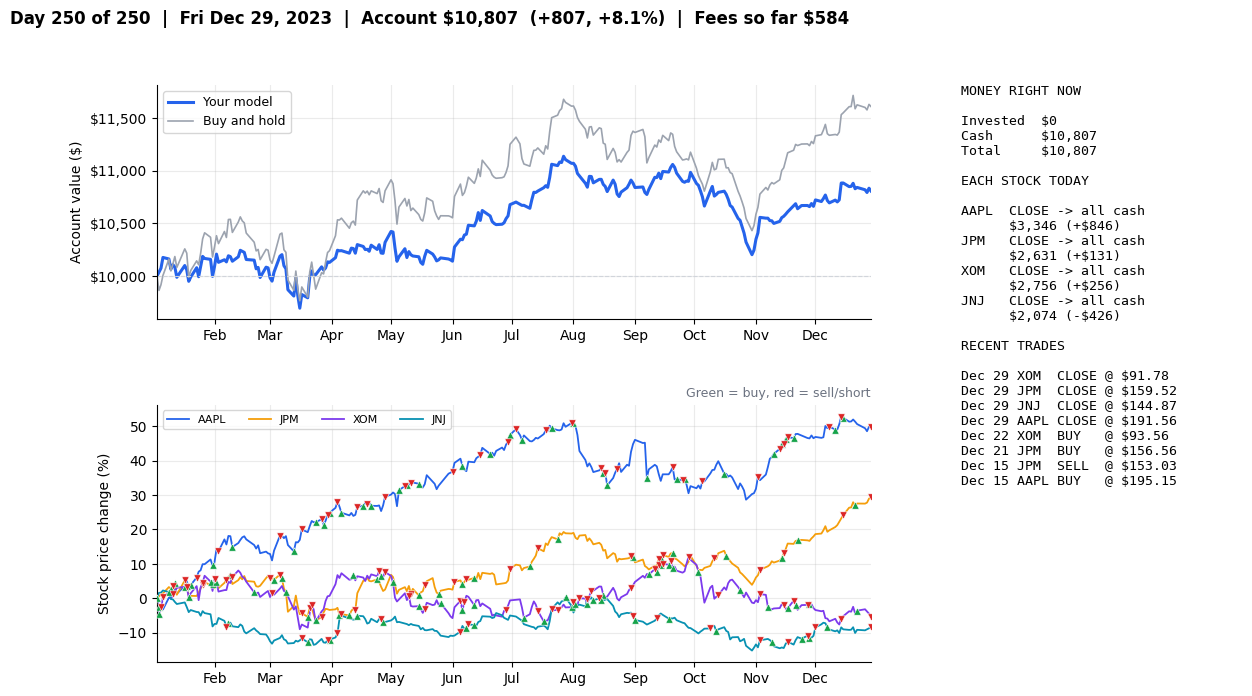


📊 FINAL RESULTS


,Started with,Ended with,Profit,Trades,Fees,Buy & hold profit
Stock,,,,,,
AAPL,"$2,500","$3,346",$846,64,$199,"$1,234"
JPM,"$2,500","$2,631",$131,50,$124,$730
XOM,"$2,500","$2,756",$256,66,$183,-$141
JNJ,"$2,500","$2,074",-$426,36,$78,-$216
TOTAL,"$10,000","$10,807",$807,216,$584,"$1,607"


Net profit: $806.75 (+8.1%)   |   Buy and hold: $1,606.91 (+16.1%)
Sharpe (competition score): 0.85   |   Buy and hold: 1.19
Worst drop from a peak: -8.4%


{'AAPL':                  Price  Position        Value   Hold value       Fee Action
 Date                                                                       
 2023-01-03  127.995383       0.0  2500.000000  2500.000000  0.000000   HOLD
 2023-01-04  124.664839       1.0  2500.000000  2432.515451  2.497502    BUY
 2023-01-05  124.900621       0.0  2502.226092  2437.116133  2.502226   SELL
 2023-01-06  123.800252       0.0  2499.723866  2415.645247  0.000000   HOLD
 2023-01-09  128.182071       0.0  2499.723866  2501.145236  0.000000   HOLD
 ...                ...       ...          ...          ...       ...    ...
 2023-12-22  192.829099       1.0  3371.792941  3762.566626  0.000000   HOLD
 2023-12-26  191.278014       1.0  3344.670803  3732.301170  0.000000   HOLD
 2023-12-27  190.171493       1.0  3325.322272  3710.710243  0.000000   HOLD
 2023-12-28  191.801604       1.0  3353.826252  3742.517689  0.000000   HOLD
 2023-12-29  191.564523       0.0  3346.330993  3734.153768  3.34968

In [17]:
watch_trading(predict_ml, money=10_000, speed='normal')

## Step 5 · ✏️ Your workspace

**Anything goes.** Tweak an example, combine them, try a different model, add features, or start fresh.
Add as many cells as you want.

**The only rules:**
1. End up with a function named **`predict(history)`** that returns a number from -1 to 1.
2. Use only data from 2015 through 2024, for training **and** testing. Don't download anything from 2025 or later.
   That's the secret test period, and checking your model against it counts as cheating even if you didn't train on it.
3. While practicing, train with `end='2022-12-31'` so your 2023 practice score is honest.
4. Handle short histories: if there isn't enough data for your model, return `0.0` (stay in cash).
   Normal rounds give your model a year of past prices, but SpaceX only went public in June 2026,
   so in the bonus round your model starts with almost no history.

**Ideas if you're stuck:**
- Change the numbers in Example 1 (20 and 100). Does a different window work better?
- Make Example 1 short (`-1.0`) instead of sitting in cash when the trend is down.
- In Example 2, add a feature or swap `LogisticRegression` for `RandomForestClassifier`.
- Raise the 0.52 / 0.48 thresholds so the model trades less and pays fewer fees.

**Ask your AI assistant something like:**
> I'm in a stock-trading model competition. My Python function `predict(history)` gets a pandas
> DataFrame of daily Open/High/Low/Close/Volume for one unnamed stock and returns a position from
> -1 (short) to 1 (long). It trades at the next day's open with a 0.1% fee. Here's my current code: [paste].
> Suggest one improvement, explain why it might help, and keep it to past data only.

**Before you commit to a model, run `robustness_check(predict)`.** One great practice score can be luck.
This tests your model across several years and different kinds of stocks, so you can see whether its edge
holds up or only worked in one spot. It takes about a minute.

Each time you run `practice_score`, it's saved with a short note. **Write what you changed in the note.**
Your list of attempts goes in with your submission, and judges will ask you about it.

,Sharpe,Total return,Max drawdown,Trades,Fees paid
Your model,0.14,0.9%,-7.5%,22,$54
Buy and hold,1.19,16.1%,-10.7%,8,$22


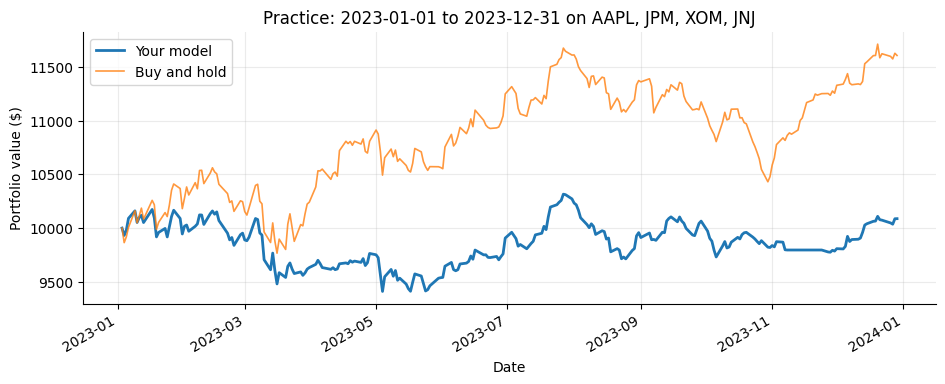

Saved as attempt #3. Sharpe: 0.14


0.13907215127560807

In [12]:
# Your code here. Start from an example or from scratch.


def predict(history):
    return predict_trend(history)    # 👈 replace with your own idea


practice_score(predict, note="describe what you changed")

Running the simulation...


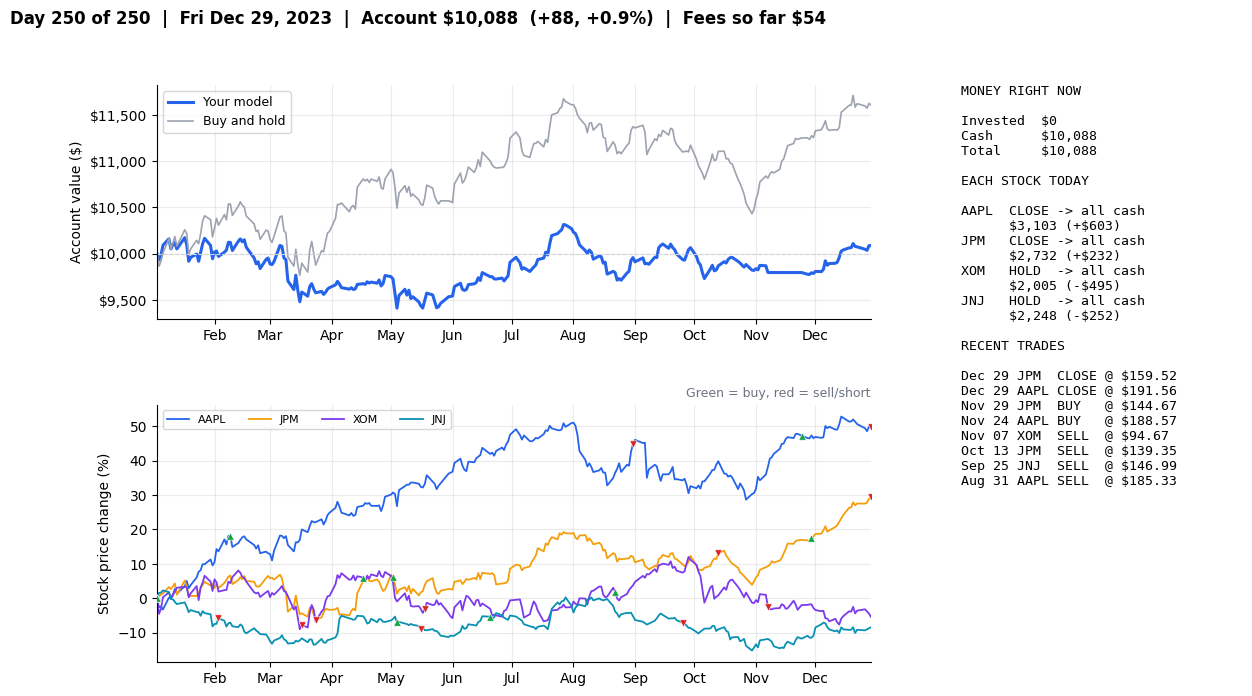


📊 FINAL RESULTS


,Started with,Ended with,Profit,Trades,Fees,Buy & hold profit
Stock,,,,,,
AAPL,"$2,500","$3,103",$603,4,$12,"$1,234"
JPM,"$2,500","$2,732",$232,6,$15,$730
XOM,"$2,500","$2,005",-$495,6,$13,-$141
JNJ,"$2,500","$2,248",-$252,6,$14,-$216
TOTAL,"$10,000","$10,088",$88,22,$54,"$1,607"


Net profit: $87.56 (+0.9%)   |   Buy and hold: $1,606.91 (+16.1%)
Sharpe (competition score): 0.14   |   Buy and hold: 1.19
Worst drop from a peak: -7.5%


{'AAPL':                  Price  Position        Value   Hold value       Fee Action
 Date                                                                       
 2023-01-03  127.995383       0.0  2500.000000  2500.000000  0.000000   HOLD
 2023-01-04  124.664839       0.0  2500.000000  2432.515451  0.000000   HOLD
 2023-01-05  124.900621       0.0  2500.000000  2437.116133  0.000000   HOLD
 2023-01-06  123.800252       0.0  2500.000000  2415.645247  0.000000   HOLD
 2023-01-09  128.182071       0.0  2500.000000  2501.145236  0.000000   HOLD
 ...                ...       ...          ...          ...       ...    ...
 2023-12-22  192.829099       1.0  3126.598521  3762.566626  0.000000   HOLD
 2023-12-26  191.278014       1.0  3101.448686  3732.301170  0.000000   HOLD
 2023-12-27  190.171493       1.0  3083.507167  3710.710243  0.000000   HOLD
 2023-12-28  191.801604       1.0  3109.938358  3742.517689  0.000000   HOLD
 2023-12-29  191.564523       0.0  3102.988149  3734.153768  3.10609

In [13]:
# Watch your model trade 2023, then see the results. Change stocks, dates, or money if you want:
# watch_trading(predict, stocks=['NVDA', 'PLUG', 'KO'], start='2024-01-01', end='2024-12-31', money=25_000)
watch_trading(predict, money=10_000, speed='normal')

In [14]:
# Does your model hold up across different years and stocks? (takes about a minute)
robustness_check(predict, note="describe this version")

Testing across years...
Testing across stock groups in 2024...


,Stocks,Your Sharpe,Buy & hold Sharpe,Your return,Honest?
Test,,,,,
2020,"JPM, XOM, PFE, CROX, M",-0.02,0.14,-2.4%,no: model saw this data
2021,"JPM, XOM, PFE, CROX, M",2.01,2.28,63.5%,no: model saw this data
2022,"JPM, XOM, PFE, CROX, M",1.06,0.28,17.5%,no: model saw this data
2023,"JPM, XOM, PFE, CROX, M",-0.28,-0.19,-4.6%,yes
2024,"JPM, XOM, PFE, CROX, M",0.97,0.67,12.2%,yes
Big tech (2024),"AAPL, MSFT, NVDA, META",1.88,1.99,65.5%,yes
Steady (2024),"JNJ, PG, KO, DUK",0.50,0.82,4.6%,yes
Struggling (2024),"INTC, F, M, HOG",-1.54,-0.93,-23.5%,yes
Volatile (2024),"PLUG, AAL, CROX, BA",0.98,-0.04,13.9%,yes


Honest tests: 6. Positive Sharpe in 4. Beat buy-and-hold in 2.
Typical (median) honest Sharpe: 0.73
Rows marked "no" overlap your training data. Their scores look better than they really are.
If your model is a hand-written rule that never trains on data, use:
   robustness_check(predict, trained_through=None)


,Stocks,Your Sharpe,Buy & hold Sharpe,Your return,Honest?
Test,,,,,
2020,"JPM, XOM, PFE, CROX, M",-0.017302,0.136740,-0.024382,no: model saw this data
2021,"JPM, XOM, PFE, CROX, M",2.014934,2.283861,0.634504,no: model saw this data
2022,"JPM, XOM, PFE, CROX, M",1.062624,0.277024,0.175121,no: model saw this data
2023,"JPM, XOM, PFE, CROX, M",-0.283414,-0.186471,-0.045607,yes
2024,"JPM, XOM, PFE, CROX, M",0.966451,0.665155,0.121893,yes
Big tech (2024),"AAPL, MSFT, NVDA, META",1.884491,1.988250,0.655499,yes
Steady (2024),"JNJ, PG, KO, DUK",0.497354,0.816259,0.045557,yes
Struggling (2024),"INTC, F, M, HOG",-1.541588,-0.934497,-0.235304,yes
Volatile (2024),"PLUG, AAL, CROX, BA",0.984704,-0.044948,0.138742,yes


In [15]:
# Every practice run so far
show_attempts()

,Time,Note,Sharpe,Return,Trades
Attempt,,,,,
1,18:15:05,Example 1: 20-day vs 100-day average,0.139,0.0088,22
2,18:15:12,"Example 2: logistic regression, 4 features",0.855,0.0807,216
3,18:16:14,describe what you changed,0.139,0.0088,22


## Step 6 · Submit

**Optional, but usually helps:** once you're happy with your design, retrain your model on all the
data by changing `end='2022-12-31'` to `end='2024-12-31'` and rerunning your training code. Your 2023
practice score will look great afterward because the model has now seen 2023. Ignore it; that's expected.

Then run the cell below. It checks your model, saves it to one file, and downloads it.

**Upload two files** to the folder the organizers share:
1. The `.pkl` file this cell downloads
2. This notebook: **File → Download → Download .ipynb**

In [16]:
save_submission(predict)

✅ Team_Example_submission.pkl saved and checked (0.1 MB).
   Test position on sample data: 0.0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PosixPath('/content/trading_competition/Team_Example_submission.pkl')

## Your 2-minute talk
No slides, just talk. Judges score each of these from 1 to 5:

| Topic | Be ready to say |
|---|---|
| **Model choice** | What your model looks at and why you picked it |
| **Iteration** | What you tried, including something that **didn't** work |
| **Validation** | How you tested it before submitting |
| **Training data** | Which stocks and dates you trained on |
| **Team understanding** | Anyone on the team might get a question |

### Rules
- Using any data after 2024 (for training, testing, or choosing your model) = zero for the trading score.
- If your model crashes or breaks the rules during the test, it gets zero for the trading score. Your talk still counts.
- No late submissions.
- The SpaceX bonus round is for fun and bragging rights only. It doesn't change the standings.

### Something broke?
| Problem | Fix |
|---|---|
| `NameError: ... is not defined` | Run the earlier cells first, top to bottom. |
| "must return a float" | End with `return float(your_number)`. |
| Sharpe is 0 and no trades | Your model always picks cash. Loosen its conditions. |
| Lots of trades, bad score | Fees are eating you. Trade less often. |
| Still stuck | Wave down an organizer. |